In [1]:
from google.colab import files
import pandas as pd

# Upload files from your device
uploaded = files.upload()

# Load the trading and instruments data
trading_df = pd.read_csv('project2_trading.csv')
instruments_df = pd.read_csv('project2_instruments.csv')

# Show first few rows
print("=== Trading Data Sample ===")
print(trading_df.head())
print("\n=== Instruments Data Sample ===")
print(instruments_df.head())


Saving project2_trading.csv to project2_trading.csv
Saving project2_instruments.csv to project2_instruments.csv
=== Trading Data Sample ===
     trade_id instrument_id                      timestamp trade_type  \
0  TRD_000001    INST_00516  2024-01-01 00:00:00.000000000       SELL   
1  TRD_000002    INST_00818  2024-01-01 00:11:39.863328777        BUY   
2  TRD_000003    INST_00283  2024-01-01 00:23:19.726657555        BUY   
3  TRD_000004    INST_00138  2024-01-01 00:34:59.589986332       SELL   
4  TRD_000005    INST_00931  2024-01-01 00:46:39.453315110       SELL   

   order_type       strategy  quantity        price  execution_price  \
0      MARKET  PAIRS_TRADING     86786  2366.978206      4228.998055   
1       LIMIT  PAIRS_TRADING     44460   245.020274      1939.500465   
2       LIMIT      ARBITRAGE     69063  1182.449102      2909.052347   
3  STOP_LIMIT  PAIRS_TRADING      5099  3582.864991       717.500193   
4      MARKET  MARKET_MAKING     16791   434.698012      3995

In [2]:
# Convert timestamp to datetime
trading_df['timestamp'] = pd.to_datetime(trading_df['timestamp'])

# Sort by instrument and timestamp
trading_df = trading_df.sort_values(by=['instrument_id', 'timestamp'])


In [3]:
# Create a weekly resampled price dataset
weekly_prices = trading_df.set_index('timestamp').groupby('instrument_id')['price'].resample('W').last().unstack(0)

print("=== Weekly Prices (sample) ===")
print(weekly_prices.head())


=== Weekly Prices (sample) ===
instrument_id   INST_00001   INST_00002   INST_00003   INST_00004  \
timestamp                                                           
2024-01-07     3675.102693  3875.920920  2458.676300          NaN   
2024-01-14     2673.937193          NaN          NaN  1165.890622   
2024-01-21     2770.098842  3759.718512  3586.511988          NaN   
2024-01-28             NaN          NaN   417.492727  1853.763706   
2024-02-04             NaN  4036.711189   171.715269          NaN   

instrument_id   INST_00005   INST_00006   INST_00007   INST_00008  INST_00009  \
timestamp                                                                       
2024-01-07             NaN  3567.504523          NaN  4194.107767         NaN   
2024-01-14     3623.815771          NaN          NaN   736.798036         NaN   
2024-01-21             NaN  1263.089425  4866.766263          NaN         NaN   
2024-01-28             NaN          NaN          NaN          NaN         NaN   

In [4]:
# Calculate weekly returns
weekly_returns = weekly_prices.pct_change().fillna(0)

print("=== Weekly Returns (sample) ===")
print(weekly_returns.head())


=== Weekly Returns (sample) ===
instrument_id  INST_00001  INST_00002  INST_00003  INST_00004  INST_00005  \
timestamp                                                                   
2024-01-07       0.000000    0.000000    0.000000    0.000000    0.000000   
2024-01-14      -0.272418    0.000000    0.000000    0.000000    0.000000   
2024-01-21       0.035963   -0.029981    0.458717    0.000000    0.000000   
2024-01-28       0.000000    0.000000   -0.883594    0.589998    0.000000   
2024-02-04       0.000000    0.073674   -0.588699    0.000000   -0.292426   

instrument_id  INST_00006  INST_00007  INST_00008  INST_00009  INST_00010  \
timestamp                                                                   
2024-01-07       0.000000    0.000000    0.000000         0.0    0.000000   
2024-01-14       0.000000    0.000000   -0.824325         0.0   -0.801634   
2024-01-21      -0.645946    0.000000    0.000000         0.0    0.000000   
2024-01-28       0.000000    0.000000    0.

/tmp/ipython-input-2143079395.py:2: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  weekly_returns = weekly_prices.pct_change().fillna(0)


In [5]:
# Calculate weekly returns
weekly_returns = weekly_prices.pct_change().fillna(0)

print("=== Weekly Returns (sample) ===")
print(weekly_returns.head())


=== Weekly Returns (sample) ===
instrument_id  INST_00001  INST_00002  INST_00003  INST_00004  INST_00005  \
timestamp                                                                   
2024-01-07       0.000000    0.000000    0.000000    0.000000    0.000000   
2024-01-14      -0.272418    0.000000    0.000000    0.000000    0.000000   
2024-01-21       0.035963   -0.029981    0.458717    0.000000    0.000000   
2024-01-28       0.000000    0.000000   -0.883594    0.589998    0.000000   
2024-02-04       0.000000    0.073674   -0.588699    0.000000   -0.292426   

instrument_id  INST_00006  INST_00007  INST_00008  INST_00009  INST_00010  \
timestamp                                                                   
2024-01-07       0.000000    0.000000    0.000000         0.0    0.000000   
2024-01-14       0.000000    0.000000   -0.824325         0.0   -0.801634   
2024-01-21      -0.645946    0.000000    0.000000         0.0    0.000000   
2024-01-28       0.000000    0.000000    0.

/tmp/ipython-input-2143079395.py:2: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  weekly_returns = weekly_prices.pct_change().fillna(0)


In [8]:
# Calculate expected (average) weekly return for each instrument
expected_returns = weekly_returns.mean()

# Convert to DataFrame for readability
expected_returns_df = expected_returns.reset_index()
expected_returns_df.columns = ['instrument_id', 'expected_return']

# Show first 10 instruments
print(expected_returns_df.head(10))


  instrument_id  expected_return
0    INST_00001         0.321966
1    INST_00002         0.400862
2    INST_00003         0.806425
3    INST_00004         0.188128
4    INST_00005         0.084930
5    INST_00006         0.160786
6    INST_00007         0.217274
7    INST_00008         0.566316
8    INST_00009         0.555419
9    INST_00010         0.199087


In [9]:
# Calculate covariance matrix of weekly returns
cov_matrix = weekly_returns.cov()

# Show the shape (it will be 1500 x 1500 since we have 1500 instruments)
print("Covariance Matrix Shape:", cov_matrix.shape)

# Show a small sample (first 5x5)
print(cov_matrix.iloc[:5, :5])


Covariance Matrix Shape: (1500, 1500)
instrument_id  INST_00001  INST_00002  INST_00003  INST_00004  INST_00005
instrument_id                                                            
INST_00001       2.060545   -0.412314   -0.318903   -0.092374   -0.016232
INST_00002      -0.412314    3.317634    3.971752    0.145775   -0.087618
INST_00003      -0.318903    3.971752   10.703363   -0.132864   -0.109028
INST_00004      -0.092374    0.145775   -0.132864    0.530739   -0.110044
INST_00005      -0.016232   -0.087618   -0.109028   -0.110044    0.264813


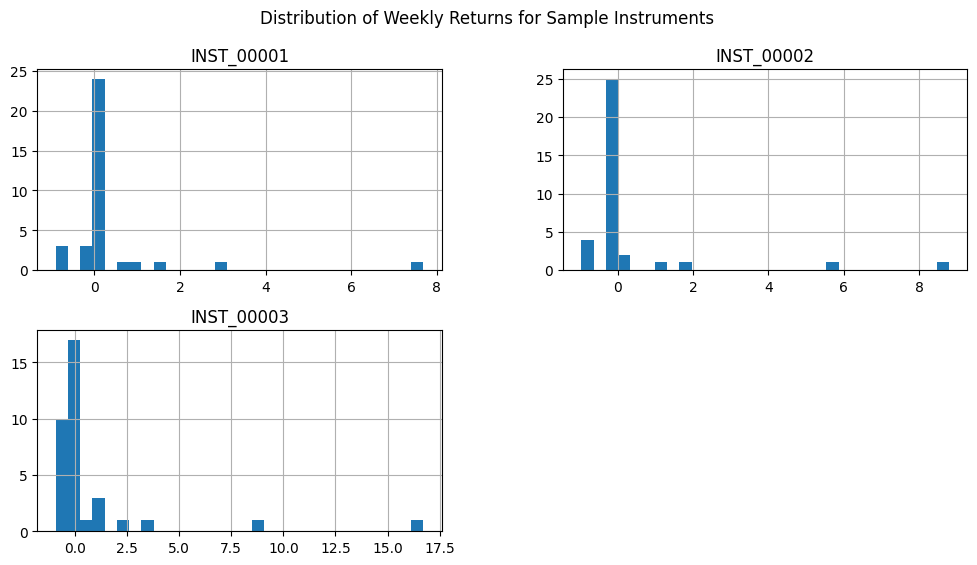

In [10]:
import matplotlib.pyplot as plt

# Pick a few instruments to visualize
sample_instruments = ['INST_00001', 'INST_00002', 'INST_00003']

weekly_returns[sample_instruments].hist(bins=30, figsize=(12,6))
plt.suptitle("Distribution of Weekly Returns for Sample Instruments")
plt.show()


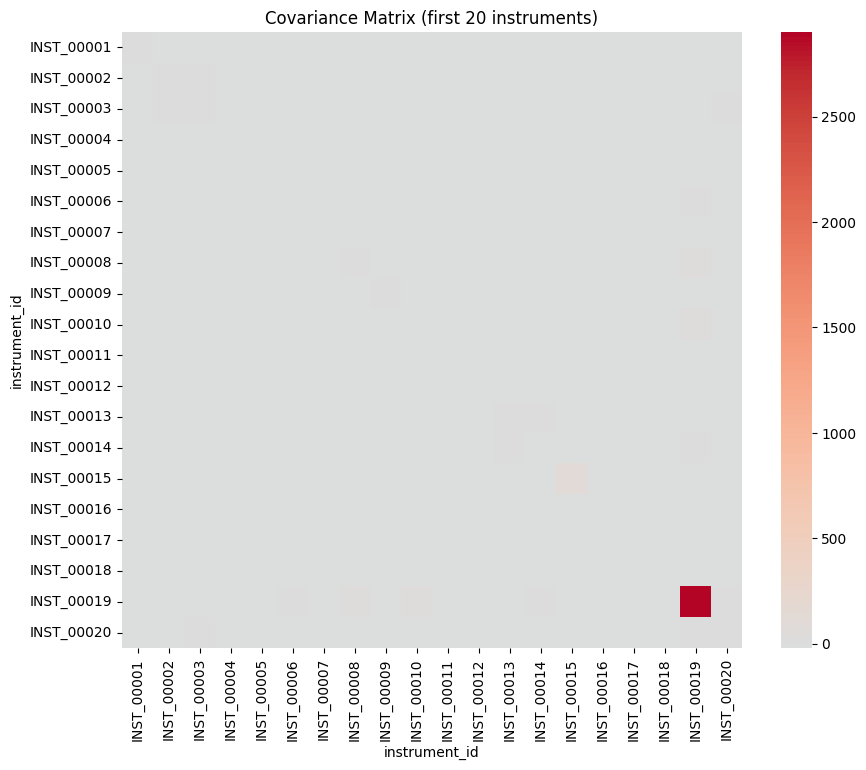

In [11]:
import seaborn as sns

plt.figure(figsize=(10,8))
sns.heatmap(cov_matrix.iloc[:20, :20], cmap="coolwarm", center=0)
plt.title("Covariance Matrix (first 20 instruments)")
plt.show()


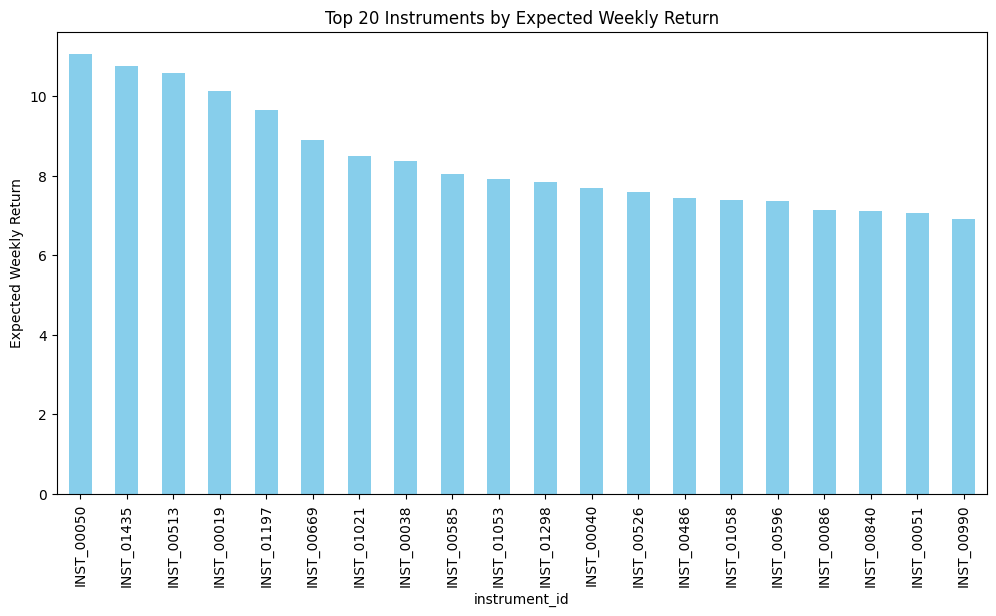

In [12]:
# Sort by expected return
top_returns = expected_returns.sort_values(ascending=False).head(20)

plt.figure(figsize=(12,6))
top_returns.plot(kind='bar', color="skyblue")
plt.title("Top 20 Instruments by Expected Weekly Return")
plt.ylabel("Expected Weekly Return")
plt.show()


In [13]:
from google.colab import files
import pandas as pd

# Upload files from your device
uploaded = files.upload()

# Load the trading and instruments data
trading_df = pd.read_csv('project2_trading.csv')
instruments_df = pd.read_csv('project2_instruments.csv')

# Convert timestamp to datetime
trading_df['timestamp'] = pd.to_datetime(trading_df['timestamp'])

# Sort values
trading_df = trading_df.sort_values(by=['instrument_id', 'timestamp'])

print("=== Trading Data Sample ===")
print(trading_df.head())
print("\n=== Instruments Data Sample ===")
print(instruments_df.head())


Saving project2_trading.csv to project2_trading (1).csv
Saving project2_instruments.csv to project2_instruments (1).csv
=== Trading Data Sample ===
        trade_id instrument_id                     timestamp trade_type  \
744   TRD_000745    INST_00001 2024-01-07 00:38:18.316610553       SELL   
998   TRD_000999    INST_00001 2024-01-09 02:01:03.602120070       SELL   
2381  TRD_002382    INST_00001 2024-01-20 06:52:54.585819527       SELL   
5451  TRD_005452    INST_00001 2024-02-14 03:42:35.005166839        BUY   
5492  TRD_005493    INST_00001 2024-02-14 11:40:49.401646722        BUY   

      order_type        strategy  quantity        price  execution_price  \
744        LIMIT  MEAN_REVERSION     50614  3675.102693      3763.888728   
998       MARKET  MEAN_REVERSION     37589  2673.937193      4681.986872   
2381       LIMIT   MARKET_MAKING     74821  2770.098842      2301.025061   
5451  STOP_LIMIT  MEAN_REVERSION     86136  2054.992498        11.933106   
5492       LIMIT     

In [17]:
# Create a monthly resampled price dataset
monthly_prices = trading_df.set_index('timestamp').groupby('instrument_id')['price'].resample('M').last().unstack(0)

print("=== Monthly Prices (sample) ===")
print(monthly_prices.head())


/tmp/ipython-input-1221602593.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_prices = trading_df.set_index('timestamp').groupby('instrument_id')['price'].resample('M').last().unstack(0)


=== Monthly Prices (sample) ===
instrument_id   INST_00001   INST_00002   INST_00003   INST_00004  \
timestamp                                                           
2024-01-31     2770.098842  3759.718512   417.492727  1853.763706   
2024-02-29     3036.364389  4488.228875   757.444218          NaN   
2024-03-31      765.108641  4730.559579  2601.454285  2549.610344   
2024-04-30     1650.818121  3621.391694   884.827613  4995.956046   
2024-05-31     3757.967780  2795.258045   676.025392  3712.768480   

instrument_id   INST_00005   INST_00006   INST_00007   INST_00008  \
timestamp                                                           
2024-01-31     3623.815771  4934.642543  4866.766263   736.798036   
2024-02-29     3792.509485   646.698424  2057.656314  1772.911141   
2024-03-31     2434.001006  3455.808108  3854.098338  1569.982449   
2024-04-30     2007.443888  1770.922356   559.079562          NaN   
2024-05-31     2606.133791  3134.309764  3740.407330  4022.930789   



In [18]:
# Calculate monthly returns
monthly_returns = monthly_prices.pct_change(fill_method=None).fillna(0)

print("=== Monthly Returns (sample) ===")
print(monthly_returns.head())


=== Monthly Returns (sample) ===
instrument_id  INST_00001  INST_00002  INST_00003  INST_00004  INST_00005  \
timestamp                                                                   
2024-01-31       0.000000    0.000000    0.000000    0.000000    0.000000   
2024-02-29       0.096121    0.193767    0.814269    0.000000    0.046551   
2024-03-31      -0.748018    0.053993    2.434516    0.000000   -0.358208   
2024-04-30       1.157626   -0.234469   -0.659872    0.959498   -0.175249   
2024-05-31       1.276428   -0.228126   -0.235981   -0.256845    0.298235   

instrument_id  INST_00006  INST_00007  INST_00008  INST_00009  INST_00010  \
timestamp                                                                   
2024-01-31       0.000000    0.000000    0.000000    0.000000    0.000000   
2024-02-29      -0.868947   -0.577203    1.406238   39.000310   -0.642671   
2024-03-31       4.343771    0.873053   -0.114461   -0.124637    0.234059   
2024-04-30      -0.487552   -0.854939    0

In [19]:
# Calculate expected (average) monthly return for each instrument
expected_returns = monthly_returns.mean()

# Convert to DataFrame for readability
expected_returns_df = expected_returns.reset_index()
expected_returns_df.columns = ['instrument_id', 'expected_return']

print("=== Expected Monthly Returns (first 10) ===")
print(expected_returns_df.head(10))


=== Expected Monthly Returns (first 10) ===
  instrument_id  expected_return
0    INST_00001         1.354078
1    INST_00002         0.024723
2    INST_00003         0.275628
3    INST_00004         0.094355
4    INST_00005         0.048971
5    INST_00006         0.358588
6    INST_00007         0.970966
7    INST_00008         0.208057
8    INST_00009         4.982263
9    INST_00010         0.112498


In [20]:
# Calculate covariance matrix of monthly returns
cov_matrix = monthly_returns.cov()

print("Covariance Matrix Shape:", cov_matrix.shape)
print(cov_matrix.iloc[:5, :5])  # show first 5x5 block


Covariance Matrix Shape: (1500, 1500)
instrument_id  INST_00001  INST_00002  INST_00003  INST_00004  INST_00005
instrument_id                                                            
INST_00001       7.760757   -0.178688   -1.681894    0.226228    0.140605
INST_00002      -0.178688    0.044692    0.125787   -0.033041    0.016436
INST_00003      -1.681894    0.125787    1.201200   -0.132959   -0.079420
INST_00004       0.226228   -0.033041   -0.132959    0.142405   -0.039863
INST_00005       0.140605    0.016436   -0.079420   -0.039863    0.060055


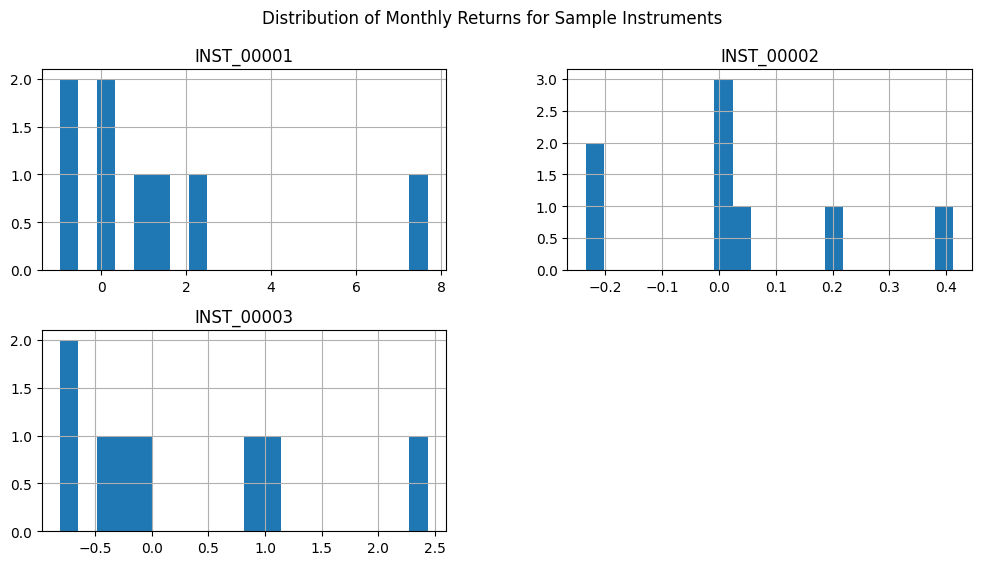

In [21]:
import matplotlib.pyplot as plt

# Pick a few instruments to visualize
sample_instruments = ['INST_00001', 'INST_00002', 'INST_00003']

monthly_returns[sample_instruments].hist(bins=20, figsize=(12,6))
plt.suptitle("Distribution of Monthly Returns for Sample Instruments")
plt.show()


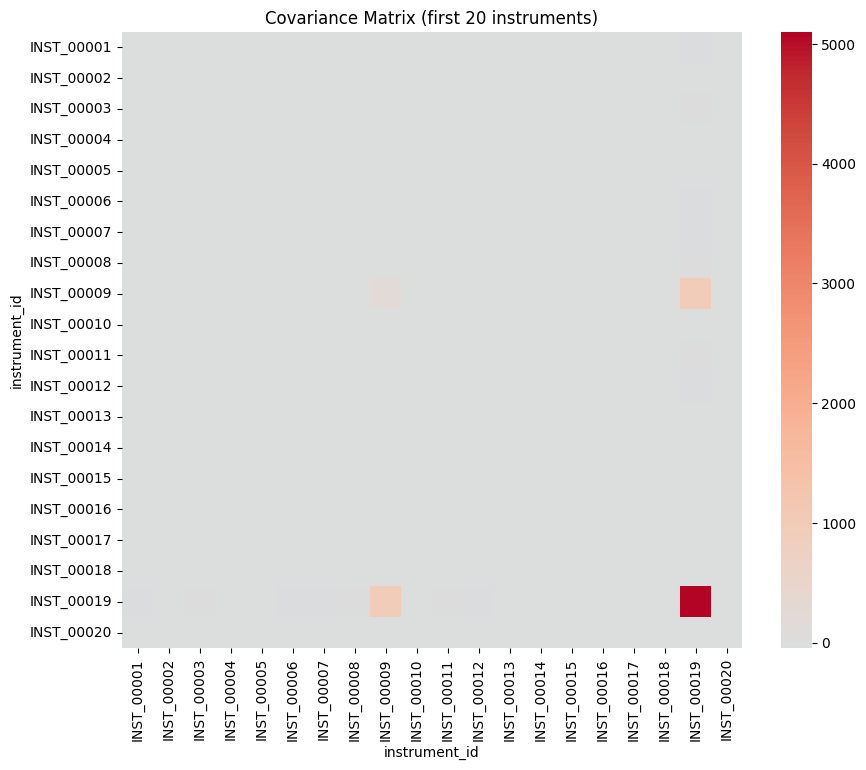

In [22]:
import seaborn as sns

plt.figure(figsize=(10,8))
sns.heatmap(cov_matrix.iloc[:20, :20], cmap="coolwarm", center=0)
plt.title("Covariance Matrix (first 20 instruments)")
plt.show()


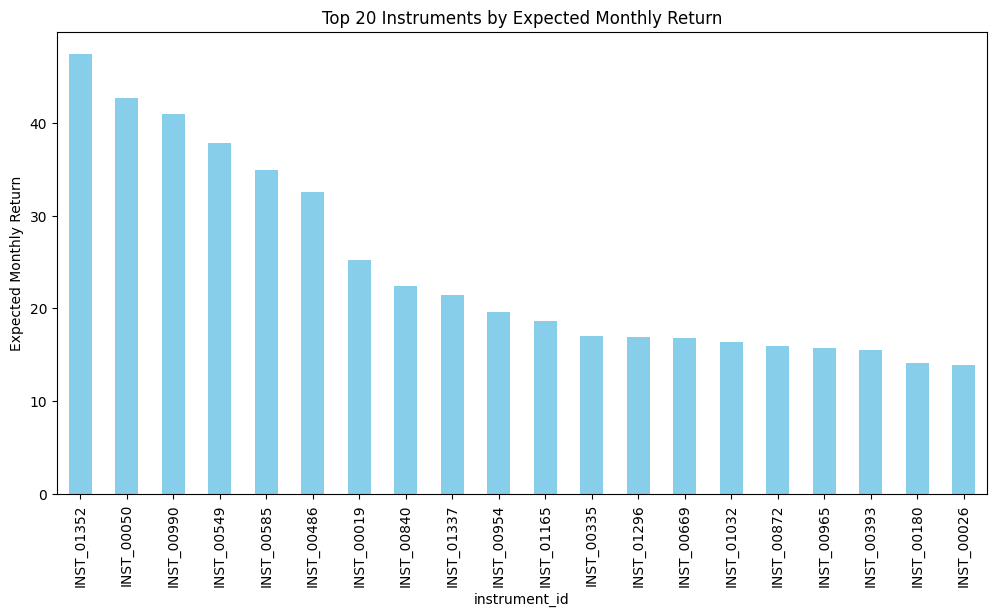

In [23]:
# Sort by expected return
top_returns = expected_returns.sort_values(ascending=False).head(20)

plt.figure(figsize=(12,6))
top_returns.plot(kind='bar', color="skyblue")
plt.title("Top 20 Instruments by Expected Monthly Return")
plt.ylabel("Expected Monthly Return")
plt.show()
